# Liveness: test + train lại (v1 -> v2)

Notebook này làm 3 việc, chạy từ trên xuống:

1. **Test v1** (model hiện tại): in ảnh ra, vẽ khung quanh từng khuôn mặt, **xanh = REAL, đỏ = FAKE** kèm score.
2. **Dựng data** từ ảnh của nhóm (mặt thật + mặt trên màn hình điện thoại) rồi **fine-tune từ v1** thành `liveness_v2.pt`.
3. **Test lại bằng v2** và so sánh với v1.

Quy ước: label 1 = live (real), 0 = spoof (fake). Score = P(live). Mặt được coi là REAL khi `score >= threshold`.

**Cần biết trước khi tin kết quả**
- Hiện chỉ có ~3 mặt giả (mặt trên điện thoại). Train trên 3 ảnh rồi test lại chính 3 ảnh đó là vô nghĩa: model chỉ nhớ lại. Notebook sẽ gắn cảnh báo "đã dùng khi train" lên ảnh nào đã nằm trong tập train.
- Muốn số liệu đáng tin cần thêm ảnh giả chụp bằng camera của nhóm (vài chục ảnh, nhiều người, nhiều góc), và để riêng một số ảnh/người làm tập dev + test.
- v2 được lưu thành file **mới**, không ghi đè v1.

## 0. Cài đặt (chạy 1 lần)

In [10]:
# Cài xong mà trước đó đã import cv2 thì Restart kernel rồi chạy lại.
%pip install -q "opencv-python<5" pillow-heif matplotlib
# torch + torchvision: Colab có sẵn. Máy local chưa có thì chạy thêm:  %pip install torch torchvision

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Cấu hình đường dẫn và tham số

In [11]:
from pathlib import Path

def find_repo():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "ml" / "anti_spoofing").is_dir():
            return p
    return None

REPO = find_repo()
# REPO = Path(r"D:\Projects\Facial_Recognition_TeamProject")   # bỏ comment nếu dòng trên ra None
assert REPO is not None, "Không tìm thấy repo: đặt REPO bằng tay ở dòng comment phía trên"

DATA_DIR   = REPO / "data" / "AppliedML"
WEIGHTS_V1 = REPO / "weights" / "liveness_mobilenetv2.pt"
WEIGHTS_V2 = REPO / "weights" / "liveness_v2.pt"   # file mới, không ghi đè v1
WORK       = REPO / "own_data"                      # crop sinh ra từ ảnh của nhóm
OUT_DIR    = REPO / "test_out"                      # ảnh có khung được lưu ở đây

# Ảnh để vẽ khung REAL/FAKE (sửa tự do: ảnh, hoặc cả thư mục qua list_images())
TEST_IMAGES = [DATA_DIR / "Hồng Minh" / n
               for n in ["fake_image.jpg", "fake_image2.jpg", "fake_image3.jpg", "fake_image4.jpg"]]

# --- chia train / dev -------------------------------------------------------------
# Mặt thật: chia THEO NGƯỜI (người trong DEV_PERSONS chỉ nằm ở dev).
# Mặt giả (phone): chia theo ảnh gốc (stem tên file) vì hiện chỉ có 1 người chụp fake.
DEV_PERSONS    = ["Mai Chi"]          # tên thư mục người trong data/AppliedML
DEV_FAKE_STEMS = ["fake_image4"]      # ảnh fake chỉ dùng làm dev, không train

# (tuỳ chọn) trộn thêm một ít LCC-FASD để model không quên dữ liệu cũ. None = không dùng.
LCC_ROOT = None                        # ví dụ Path(r"D:\datasets\LCC_FASD")
LCC_PER_CLASS = 400                    # số ảnh mỗi lớp lấy từ LCC (train), 1/4 số đó cho dev

# --- huấn luyện -------------------------------------------------------------------
EPOCHS, LR, BATCH, FREEZE_UNTIL = 6, 1e-4, 16, 14
SEED = 42

## 2. Model, phát hiện mặt (kể cả nghiêng), hàm tính score

In [12]:
import random, shutil, json, re
from collections import Counter, deque

import numpy as np
import cv2
import torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image, ImageOps
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms as T
from torchvision.models import mobilenet_v2
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

try:  # mở được ảnh HEIC của iPhone
    from pillow_heif import register_heif_opener
    register_heif_opener()
except ImportError:
    print("Chưa có pillow-heif: ảnh .HEIC sẽ không mở được")

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, "| repo:", REPO)

IMG_SIZE = 224
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)   # giống ml/anti_spoofing/model.py
IMG_EXT = {".jpg", ".jpeg", ".jfif", ".png", ".bmp", ".webp", ".heic", ".heif"}


# ---------- model (khớp với ml/anti_spoofing/model.py và backend/.../liveness.py) ----------
def build_model(dropout=0.2):
    m = mobilenet_v2(weights=None)
    m.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(m.classifier[1].in_features, 1))
    return m

def load_ckpt(path):
    ck = torch.load(path, map_location="cpu", weights_only=True)   # file train trên GPU vẫn load được trên CPU
    m = build_model()
    m.load_state_dict(ck["state_dict"])
    return m.to(DEVICE).eval(), ck

def prep(crop_bgr):
    img = Image.fromarray(np.ascontiguousarray(crop_bgr[..., ::-1])).resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
    x = torch.from_numpy(np.asarray(img, dtype=np.float32) / 255.0).permute(2, 0, 1)
    return (x - torch.tensor(MEAN).view(3, 1, 1)) / torch.tensor(STD).view(3, 1, 1)

@torch.inference_mode()
def score_crops(model, crops_bgr):
    """P(live) cho từng crop (mỗi crop 1 ảnh, không lấy trung bình 10 khung như check())."""
    if not crops_bgr:
        return np.array([])
    model.eval()
    x = torch.stack([prep(c) for c in crops_bgr]).to(DEVICE)
    return torch.sigmoid(model(x).squeeze(1)).cpu().numpy()


# ---------- phát hiện mặt: Haar, thử xoay ảnh +-15/30/45 độ để bắt mặt nghiêng ----------
assert hasattr(cv2, "CascadeClassifier"), 'OpenCV 5 không có Haar. Chạy: pip install "opencv-python<5"'
_xml = "haarcascade_frontalface_default.xml"
_cands = [Path.cwd() / _xml, REPO / "ml" / "anti_spoofing" / _xml, Path(getattr(cv2.data, "haarcascades", "")) / _xml]
CASCADE = next((cv2.CascadeClassifier(str(p)) for p in _cands if p.is_file()), None)
assert CASCADE is not None and not CASCADE.empty(), "Không tìm thấy haarcascade_frontalface_default.xml"

ANGLES = [0, 15, -15, 30, -30, 45, -45]
MARGIN = 0.25   # viền quanh mặt, giống try_liveness.py

def load_bgr(path):
    img = ImageOps.exif_transpose(Image.open(path)).convert("RGB")   # theo cờ xoay của điện thoại
    return np.ascontiguousarray(np.asarray(img)[..., ::-1])

def list_images(folder):
    return sorted(p for p in Path(folder).rglob("*") if p.suffix.lower() in IMG_EXT)

def _haar(bgr, neighbors):
    """Các hộp (x, y, w, h) theo pixel của bgr. Dò trên bản thu nhỏ 640px cho nhanh."""
    h, w = bgr.shape[:2]
    s = 640.0 / max(h, w) if max(h, w) > 640 else 1.0
    small = cv2.resize(bgr, None, fx=s, fy=s, interpolation=cv2.INTER_AREA) if s < 1 else bgr
    gray = cv2.equalizeHist(cv2.cvtColor(small, cv2.COLOR_BGR2GRAY))
    m = max(24, int(min(gray.shape) * 0.05))
    return [(x / s, y / s, fw / s, fh / s) for x, y, fw, fh in CASCADE.detectMultiScale(gray, 1.1, neighbors, minSize=(m, m))]

def _rotate(bgr, angle):
    h, w = bgr.shape[:2]
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
    c, s = abs(M[0, 0]), abs(M[0, 1])
    nw, nh = int(h * s + w * c), int(h * c + w * s)
    M[0, 2] += nw / 2 - w / 2
    M[1, 2] += nh / 2 - h / 2
    return cv2.warpAffine(bgr, M, (nw, nh), borderValue=(0, 0, 0)), M

def _square_crop(img, cx, cy, side):
    h, w = img.shape[:2]
    x0, x1 = int(max(0, cx - side / 2)), int(min(w, cx + side / 2))
    y0, y1 = int(max(0, cy - side / 2)), int(min(h, cy + side / 2))
    if x1 - x0 < 8 or y1 - y0 < 8:
        return None
    return np.ascontiguousarray(img[y0:y1, x0:x1])

def detect_faces(bgr, max_faces=6, min_support=1, neighbors0=4):
    """Mọi khuôn mặt tìm được, to nhất trước.
    Mỗi mặt: {"poly": 4 đỉnh của khung (toạ độ ảnh gốc, nghiêng theo mặt), "crop": crop đã xoay thẳng, "angle", "support"}.
    min_support = số góc xoay phải cùng bắt được mặt đó (mặt thật thường được bắt ở 2-3 góc kề nhau, khung nhầm thường chỉ 1)."""
    cands = []
    for ang in ANGLES:
        img, M = (bgr, None) if ang == 0 else _rotate(bgr, ang)
        for x, y, fw, fh in _haar(img, neighbors0 if ang == 0 else 7):
            pts = np.array([[x, y], [x + fw, y], [x + fw, y + fh], [x, y + fh]], dtype=float)
            side = max(fw, fh)
            crop = _square_crop(img, x + fw / 2, y + fh / 2, side * (1 + 2 * MARGIN))
            if crop is None:
                continue
            if M is not None:   # đưa khung về toạ độ ảnh gốc
                pts = (cv2.invertAffineTransform(M) @ np.c_[pts, np.ones(4)].T).T
            cands.append({"poly": pts, "crop": crop, "angle": ang, "size": side, "center": pts.mean(0)})
    cands.sort(key=lambda c: -c["size"])
    clusters = []   # cùng 1 mặt hay bị bắt ở nhiều góc xoay -> gom lại (tâm lệch nhỏ so với kích thước mặt)
    for c in cands:
        for cl in clusters:
            if np.hypot(*(c["center"] - cl[0]["center"])) <= 0.25 * min(c["size"], cl[0]["size"]):
                cl.append(c); break
        else:
            clusters.append([c])
    reps = []
    for cl in clusters:   # góc nghiêng của mặt = góc "ở giữa" (medoid) của các lần bắt được; hoà thì chọn góc nhỏ hơn
        if len(cl) >= min_support:
            best = min(cl, key=lambda m: (sum(abs(m["angle"] - o["angle"]) for o in cl), abs(m["angle"]), -m["size"]))
            reps.append(dict(best, support=len(cl)))
    reps.sort(key=lambda c: -c["size"])
    kept = []
    for c in reps:   # khung nhỏ nằm trong một khuôn mặt to hơn = bắt nhầm (mắt, mũi, tóc...), bỏ
        if not any(np.hypot(*(c["center"] - k["center"])) < 0.5 * k["size"] for k in kept):
            kept.append(c)
    return kept[:max_faces]


# ---------- in ảnh + vẽ khung ----------
GREEN, RED = "#16a34a", "#dc2626"

def show_predictions(paths, model, thr, tag="", seen=(), save=True):
    """Vẽ khung quanh mọi mặt: xanh REAL, đỏ FAKE. `seen` = stem ảnh đã dùng để train (sẽ bị cảnh báo)."""
    OUT_DIR.mkdir(exist_ok=True)
    rows = []
    for p in map(Path, paths):
        try:
            bgr = load_bgr(p)
        except Exception as e:
            print(f"SKIP {p.name}: {e}")
            continue
        faces = detect_faces(bgr)
        scores = score_crops(model, [f["crop"] for f in faces])
        fig, ax = plt.subplots(figsize=(9, max(3, 9 * bgr.shape[0] / bgr.shape[1])))
        ax.imshow(bgr[..., ::-1]); ax.axis("off")
        for f, s in zip(faces, scores):
            live = s >= thr
            col = GREEN if live else RED
            ax.add_patch(Polygon(f["poly"], closed=True, fill=False, edgecolor=col, linewidth=3))
            top = f["poly"][f["poly"][:, 1].argmin()]
            ax.text(top[0], top[1] - 6, f"{'REAL' if live else 'FAKE'} {s:.3f}", color="white", fontsize=12,
                    fontweight="bold", va="bottom", ha="left", bbox=dict(facecolor=col, edgecolor="none", pad=2))
        warn = "  [!] ảnh này đã dùng khi train" if p.stem in seen else ""
        ax.set_title(f"{p.name} | {tag} | threshold={thr:.4f} | {len(faces)} mặt{warn}", fontsize=10,
                     color=RED if warn else "black")
        if save:
            fig.savefig(OUT_DIR / f"{tag.replace(' ', '_')}_{p.stem}.png", dpi=110, bbox_inches="tight")
        plt.show()
        rows += [(p.name, i + 1, float(s), bool(s >= thr)) for i, s in enumerate(scores)]
    return rows

device: cpu | repo: d:\Projects\Facial_Recognition_TeamProject


## 3. Test v1 (chưa train gì)

Xanh = REAL, đỏ = FAKE, số bên cạnh là P(live). Ảnh cũng được lưu vào `test_out/`.
Hộp đỏ/xanh nằm trên vùng không phải mặt (ví dụ cạnh trên điện thoại) là Haar bắt nhầm, không phải lỗi của model liveness.

v1 threshold: 0.023884648457169533


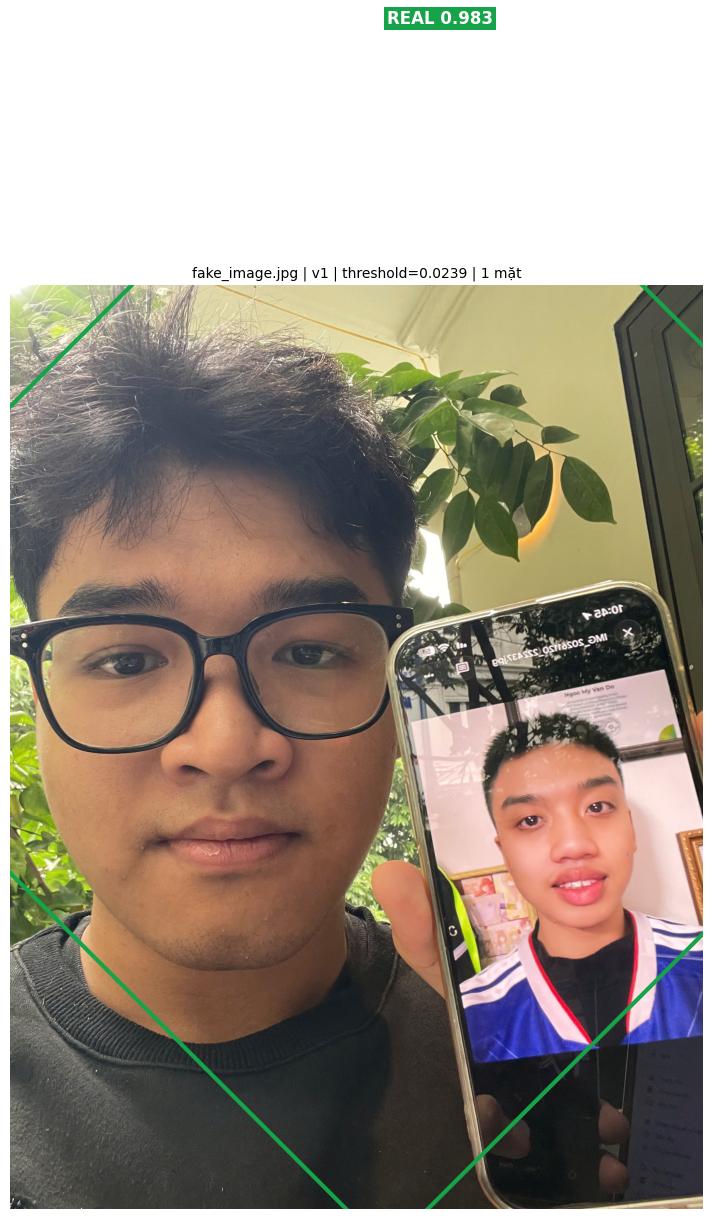

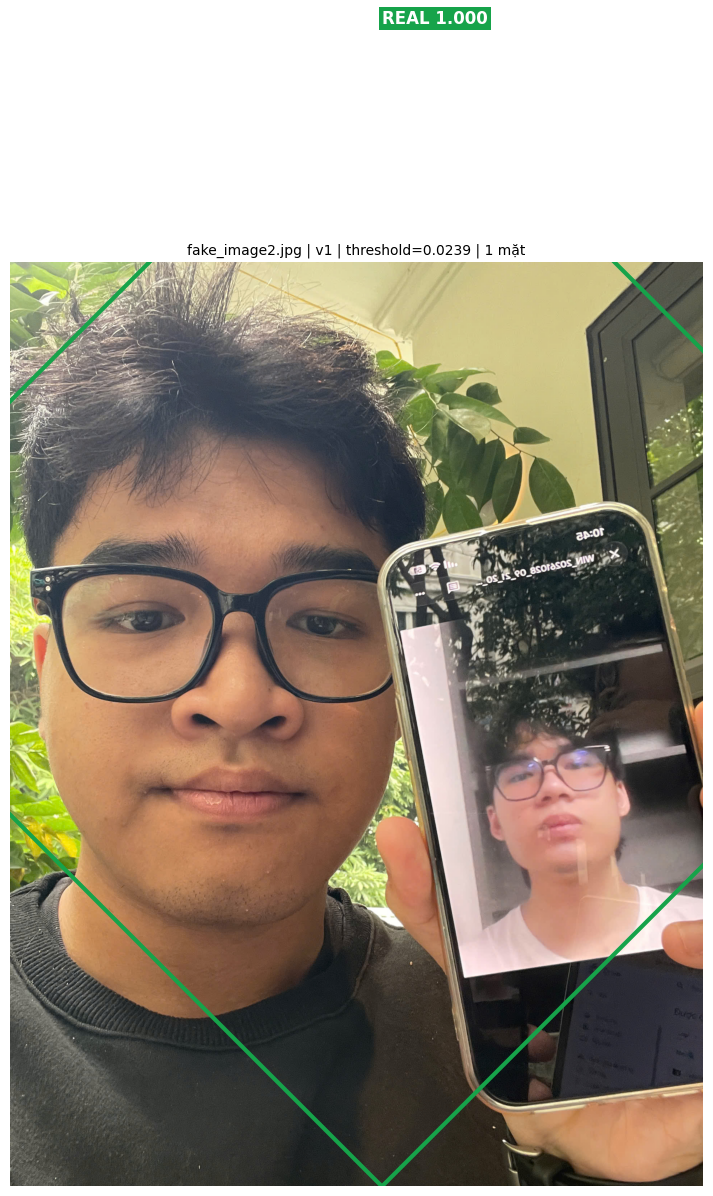

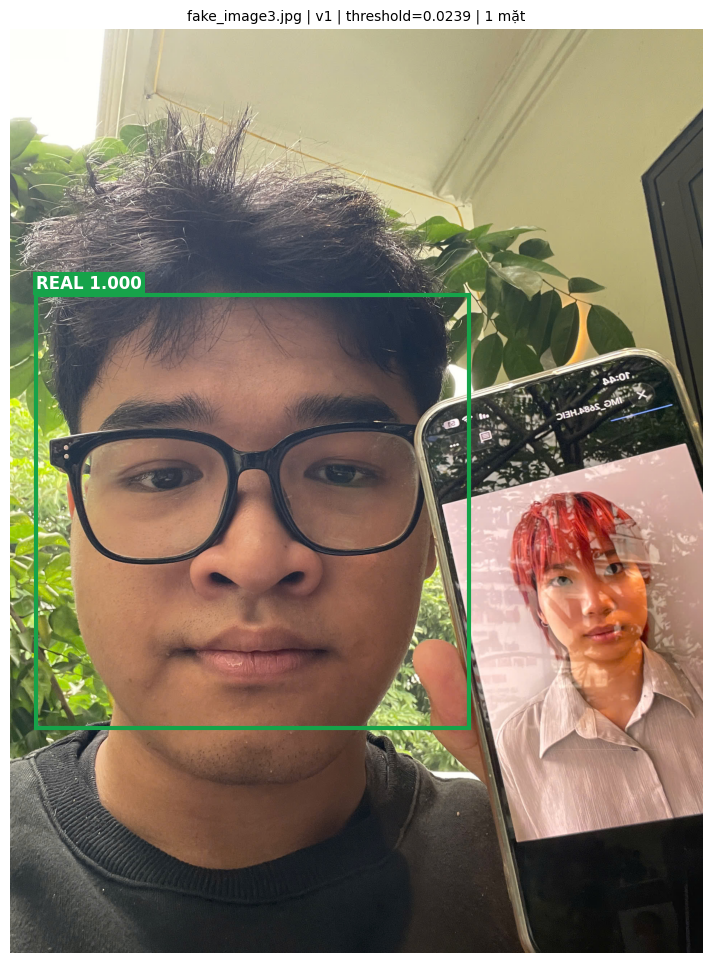

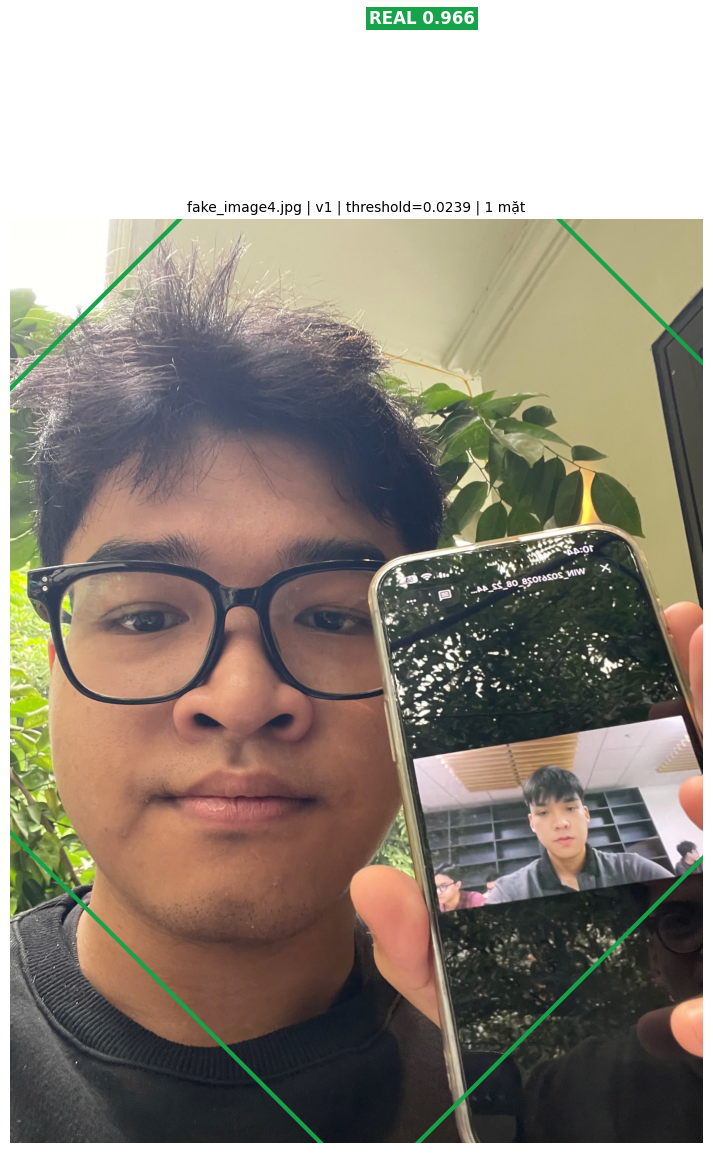

In [13]:
model_v1, ck1 = load_ckpt(WEIGHTS_V1)
THR_V1 = float(ck1["threshold"])
print("v1 threshold:", THR_V1)
rows_v1 = show_predictions(TEST_IMAGES, model_v1, THR_V1, tag="v1")

## 4. Dựng data từ ảnh của nhóm

- Mỗi ảnh trong `data/AppliedML/<người>/` (trừ `video data`, `student_card_image`, `fake_crops`) -> lấy **mặt to nhất** làm **real**.
- Ảnh tên bắt đầu bằng `fake`: mặt to nhất = người thật (real); **các mặt còn lại = mặt trên điện thoại (spoof)**.
- Mặt điện thoại mà Haar bỏ sót: crop tay, bỏ vào `data/AppliedML/fake_crops/` đặt tên `fake_image3_phone.jpg`. Tên bắt đầu bằng `dev_` thì vào dev, còn lại vào train.
- Ảnh mặt quá nghiêng/cận cảnh (tai, mũi, kính, khẩu trang che hết) thường bị bỏ qua vì Haar không bắt được: đó là hạn chế của detector, không ép vào data.
- Sau khi dựng xong **phải nhìn ô review bên dưới**: crop nào không phải mặt thật sự (ngực, áo, trần nhà, tai...) thì điền vào `EXCLUDE`. Đuôi `_s1` trong tên file spoof = chỉ 1 góc xoay bắt được, độ tin cậy thấp, kiểm tra kỹ. Crop sai mà vẫn gắn nhãn real/spoof sẽ làm hỏng model.

In [14]:
SKIP_DIRS = {"video data", "student_card_image", "fake_crops"}
SEEN_STEMS = set()   # ảnh gốc đã đóng góp crop cho tập train

def _save(img, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    Image.fromarray(np.ascontiguousarray(img[..., ::-1])).save(path, quality=95)

def build_own_data():
    if WORK.exists():
        shutil.rmtree(WORK)
    SEEN_STEMS.clear()
    skipped, n = [], Counter()
    for pdir in sorted(d for d in DATA_DIR.iterdir() if d.is_dir() and d.name.lower() not in SKIP_DIRS):
        psplit = "dev" if pdir.name in DEV_PERSONS else "train"
        for f in list_images(pdir):
            is_fake = f.stem.lower().startswith("fake")
            try:   # ảnh thường: mặt phải được >=2 góc xoay xác nhận. Ảnh fake: nới ra để bắt mặt nhỏ trên điện thoại.
                faces = detect_faces(load_bgr(f), min_support=1 if is_fake else 2, neighbors0=3 if is_fake else 4)
            except Exception as e:
                skipped.append(f"{pdir.name}/{f.name} ({e})"); continue
            if not faces:
                skipped.append(f"{pdir.name}/{f.name} (không thấy mặt)"); continue
            tag = f"{pdir.name}_{f.stem}".replace(" ", "_")
            _save(faces[0]["crop"], WORK / psplit / "real" / f"{tag}.jpg"); n[(psplit, "real")] += 1
            if psplit == "train": SEEN_STEMS.add(f.stem)
            if is_fake:
                print(f"{f.name}: tìm thấy {len(faces)} mặt (1 mặt thật + {len(faces) - 1} mặt trên điện thoại)")
                ssplit = "dev" if f.stem in DEV_FAKE_STEMS else "train"
                for k, fc in enumerate(faces[1:], start=2):
                    _save(fc["crop"], WORK / ssplit / "spoof" / f"{tag}_face{k}_s{fc['support']}.jpg"); n[(ssplit, "spoof")] += 1
                    if ssplit == "train": SEEN_STEMS.add(f.stem)
    manual = DATA_DIR / "fake_crops"
    if manual.is_dir():
        for f in list_images(manual):
            ssplit = "dev" if f.name.lower().startswith("dev_") else "train"
            _save(load_bgr(f), WORK / ssplit / "spoof" / f"manual_{f.stem}.jpg"); n[(ssplit, "spoof")] += 1
            if ssplit == "train": SEEN_STEMS.add(re.split(r"_(?:phone|crop)", f.stem)[0])
    print("crop đã lưu:", dict(n))
    print("bỏ qua:", len(skipped), "ảnh")
    for s in skipped[:30]:
        print("   ", s)

build_own_data()

fake_image.jpg: tìm thấy 1 mặt (1 mặt thật + 0 mặt trên điện thoại)
fake_image2.jpg: tìm thấy 1 mặt (1 mặt thật + 0 mặt trên điện thoại)
fake_image3.jpg: tìm thấy 1 mặt (1 mặt thật + 0 mặt trên điện thoại)
fake_image4.jpg: tìm thấy 1 mặt (1 mặt thật + 0 mặt trên điện thoại)
crop đã lưu: {('train', 'real'): 21, ('dev', 'real'): 2}
bỏ qua: 73 ảnh
    Hồng Minh/IMG_8098.HEIC (không thấy mặt)
    Hồng Minh/IMG_8099.HEIC (không thấy mặt)
    Hồng Minh/IMG_8101.HEIC (không thấy mặt)
    Hồng Minh/IMG_8102.HEIC (không thấy mặt)
    Hồng Minh/IMG_8111.HEIC (không thấy mặt)
    Hồng Minh/IMG_8112.HEIC (không thấy mặt)
    Hồng Minh/IMG_8113.HEIC (không thấy mặt)
    Hồng Minh/IMG_8114.HEIC (không thấy mặt)
    Hồng Minh/IMG_8115.HEIC (không thấy mặt)
    Mai Chi/411b0f34-d980-4f44-b852-f05513dd9caf.jpeg (không thấy mặt)
    Mai Chi/60f33ee6-19c8-4e90-b7a7-2fc0ee4ac68c.jpeg (không thấy mặt)
    Mai Chi/81a06e89-3cc6-40b0-bdd4-1220092fb06b.jpeg (không thấy mặt)
    Mai Chi/862d749a-cb3e-4d4a-b75b

train / spoof (mặt giả) : (trống)
dev / spoof (mặt giả) : (trống)


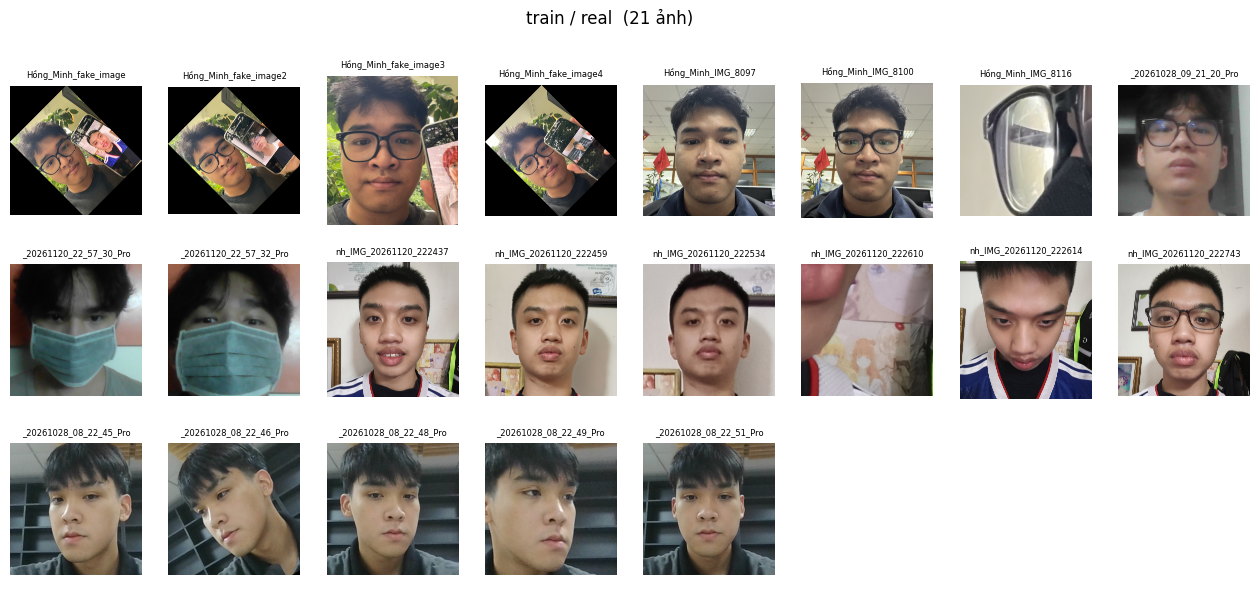

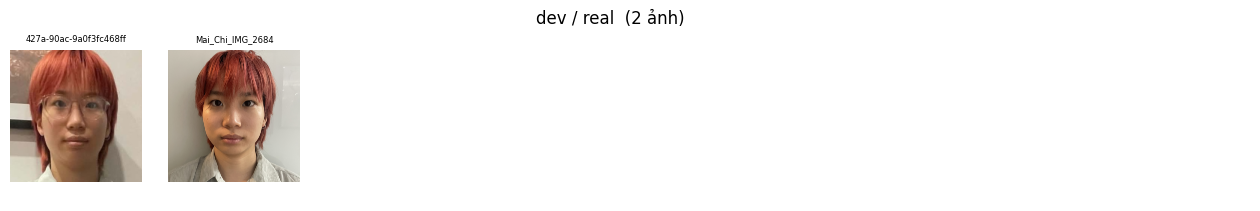

In [15]:
def show_crops(folder, cols=8, title=""):
    files = sorted(Path(folder).glob("*.jpg"))
    if not files:
        print(title, ": (trống)"); return
    rows = (len(files) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(2 * cols, 2.2 * rows), squeeze=False)
    for ax in axes.ravel(): ax.axis("off")
    for ax, f in zip(axes.ravel(), files):
        ax.imshow(Image.open(f)); ax.set_title(f.stem[-22:], fontsize=6)
    fig.suptitle(f"{title}  ({len(files)} ảnh)"); plt.show()

# Review: spoof phải là MẶT TRÊN ĐIỆN THOẠI; real phải là MẶT NGƯỜI THẬT. Cái nào sai thì ghi tên file vào EXCLUDE.
show_crops(WORK / "train" / "spoof", title="train / spoof (mặt giả)")
show_crops(WORK / "dev" / "spoof", title="dev / spoof (mặt giả)")
show_crops(WORK / "train" / "real", title="train / real")
show_crops(WORK / "dev" / "real", title="dev / real")

In [16]:
EXCLUDE = []   # ví dụ ["Hồng_Minh_fake_image_face3.jpg"]  (tên file hiện dưới mỗi crop)

for name in EXCLUDE:
    for f in WORK.rglob(name):
        f.unlink(); print("đã xoá", f)

def collect_own():
    tr, dv = [], []
    for sp, bucket in (("train", tr), ("dev", dv)):
        for cls, y in (("real", 1), ("spoof", 0)):
            bucket += [(str(p), y, "own") for p in sorted((WORK / sp / cls).glob("*.jpg"))]
    return tr, dv

def lcc_find(root, keys, depth=3):
    q = deque([(Path(root), 0)])
    while q:
        d, k = q.popleft()
        if k and any(s in d.name.lower() for s in keys):
            return d
        if k < depth:
            q.extend((c, k + 1) for c in sorted(d.iterdir()) if c.is_dir())

def lcc_sample(root, keys, per_class):
    d = lcc_find(root, keys)
    if d is None:
        print("không thấy thư mục", keys, "trong", root); return []
    by = {0: [], 1: []}
    for p in d.rglob("*"):
        if p.suffix.lower() not in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}:
            continue
        parts = [s.lower() for s in p.relative_to(d).parts[:-1]][::-1]
        for part in parts:
            if any(k in part for k in ("real", "live", "genuine")): by[1].append(str(p)); break
            if any(k in part for k in ("spoof", "fake", "attack")): by[0].append(str(p)); break
    rng = random.Random(SEED)
    return [(p, y, "lcc") for y in (0, 1) for p in rng.sample(by[y], min(per_class, len(by[y])))]

train_s, dev_s = collect_own()
if LCC_ROOT:
    train_s += lcc_sample(LCC_ROOT, ("train",), LCC_PER_CLASS)
    dev_s += lcc_sample(LCC_ROOT, ("dev", "val"), max(1, LCC_PER_CLASS // 4))

def describe(name, s):
    for src in ("own", "lcc"):
        sub = [x for x in s if x[2] == src]
        if sub:
            r = sum(1 for x in sub if x[1] == 1)
            print(f"{name:<6} {src}: {len(sub):>5} ảnh | real {r:>4} | spoof {len(sub) - r:>4}")
describe("train", train_s); describe("dev", dev_s)

n_sp_tr = sum(1 for x in train_s if x[1] == 0 and x[2] == "own")
n_sp_dv = sum(1 for x in dev_s if x[1] == 0 and x[2] == "own")
n_all_tr = sum(1 for x in train_s if x[1] == 0); n_all_dv = sum(1 for x in dev_s if x[1] == 0)
if n_all_tr == 0 or n_all_dv == 0:
    raise RuntimeError(f"Không thể train: số mặt GIẢ trong train = {n_all_tr}, trong dev = {n_all_dv}. Train chỉ với mặt thật "
                       "sẽ ra model vô nghĩa. Thêm mặt giả (crop tay vào fake_crops/ hoặc chụp thêm) rồi chạy lại mục 4.")
if n_sp_tr < 30 or n_sp_dv < 10:
    print(f"\n[!] Mặt giả tự chụp quá ít (train {n_sp_tr}, dev {n_sp_dv}). Train vẫn chạy được nhưng số liệu "
          "KHÔNG đủ để kết luận. Cần chụp thêm ảnh giả bằng camera của nhóm.")

train  own:    21 ảnh | real   21 | spoof    0
dev    own:     2 ảnh | real    2 | spoof    0


RuntimeError: Không thể train: số mặt GIẢ trong train = 0, trong dev = 0. Train chỉ với mặt thật sẽ ra model vô nghĩa. Thêm mặt giả (crop tay vào fake_crops/ hoặc chụp thêm) rồi chạy lại mục 4.

## 5. Fine-tune từ v1 -> v2

- Khởi tạo bằng trọng số v1, đóng băng các block `< FREEZE_UNTIL`, chỉ train phần cuối và head, learning rate nhỏ.
- Augmentation có xoay tới ±30° để model quen mặt nghiêng (v1 chỉ train xoay ±8°).
- Lấy epoch có dev loss thấp nhất. Threshold chọn trên dev (tối thiểu APCER+BPCER).
- Máy CPU: với vài trăm ảnh thì vài phút là xong. Có LCC thì lâu hơn.

In [ ]:
def train_tf():
    return T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.RandomHorizontalFlip(),
                      T.RandomAffine(degrees=30, translate=(0.05, 0.05), scale=(0.9, 1.1)),
                      T.ColorJitter(0.3, 0.25, 0.1), T.ToTensor(), T.Normalize(MEAN, STD)])

def eval_tf():
    return T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.ToTensor(), T.Normalize(MEAN, STD)])

class FaceDS(Dataset):
    def __init__(self, samples, tf):
        self.s, self.tf = list(samples), tf
    def __len__(self):
        return len(self.s)
    def __getitem__(self, i):
        path, y, _ = self.s[i]
        return self.tf(Image.open(path).convert("RGB")), float(y)

def balanced_sampler(samples):
    n1 = max(1, sum(1 for s in samples if s[1] == 1)); n0 = max(1, len(samples) - n1)
    w = [1.0 / n1 if s[1] == 1 else 1.0 / n0 for s in samples]
    return WeightedRandomSampler(w, num_samples=max(len(samples), 256), replacement=True)

def predict(model, samples, bs=32):
    if not samples:
        return np.array([], dtype=int), np.array([])
    dl = DataLoader(FaceDS(samples, eval_tf()), batch_size=bs, shuffle=False, num_workers=0)
    ys, ss = [], []
    model.eval()
    with torch.inference_mode():
        for x, y in dl:
            ss.append(torch.sigmoid(model(x.to(DEVICE)).squeeze(1)).cpu().numpy()); ys.append(y.numpy())
    return np.concatenate(ys).astype(int), np.concatenate(ss)

def auc(y, s):
    pos, neg = s[y == 1], s[y == 0]
    if not len(pos) or not len(neg):
        return float("nan")
    return float(((pos[:, None] > neg[None, :]).sum() + 0.5 * (pos[:, None] == neg[None, :]).sum()) / (len(pos) * len(neg)))

def rates(y, s, thr):
    live = s >= thr
    apcer = float(live[y == 0].mean()) if (y == 0).any() else float("nan")    # giả mà bị cho là thật
    bpcer = float((~live[y == 1]).mean()) if (y == 1).any() else float("nan")  # thật mà bị cho là giả
    return apcer, bpcer

def balanced_bce(y, s):
    s = np.clip(s, 1e-7, 1 - 1e-7)
    l1 = -np.log(s[y == 1]).mean() if (y == 1).any() else 0.0
    l0 = -np.log(1 - s[y == 0]).mean() if (y == 0).any() else 0.0
    return float((l1 + l0) / (2 if (y == 1).any() and (y == 0).any() else 1))

def pick_threshold(y, s):
    """Ngưỡng làm APCER+BPCER nhỏ nhất; nhiều ngưỡng hoà thì lấy giữa."""
    if len(set(y.tolist())) < 2:
        print("[!] dev chỉ có 1 lớp -> dùng threshold 0.5"); return 0.5
    u = np.unique(s)
    cand = np.concatenate([[u[0] - 1e-6], (u[:-1] + u[1:]) / 2, [u[-1] + 1e-6]])
    cost = np.array([sum(rates(y, s, t)) for t in cand])
    return float(np.median(cand[cost == cost.min()]))

def report(model, thr, samples, name):
    for src in ("own", "lcc"):
        sub = [x for x in samples if x[2] == src]
        if not sub:
            continue
        y, s = predict(model, sub)
        a, b = rates(y, s, thr)
        print(f"{name:<4} dev-{src}: n={len(y):>4} (real {int((y == 1).sum())}, spoof {int((y == 0).sum())}) | "
              f"AUC {auc(y, s):.3f} | APCER {a:.3f} (giả lọt) | BPCER {b:.3f} (thật bị chặn) | thr {thr:.4f}")

def finetune(model, train_s, dev_s, epochs, lr, freeze_until, bs):
    for i, blk in enumerate(model.features):
        for p in blk.parameters():
            p.requires_grad = i >= freeze_until
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    dl = DataLoader(FaceDS(train_s, train_tf()), batch_size=bs, sampler=balanced_sampler(train_s), num_workers=0)
    best_loss, best_state, best_ep, hist = float("inf"), None, 0, []
    for ep in range(1, epochs + 1):
        model.train()
        for i, blk in enumerate(model.features):
            if i < freeze_until:
                blk.eval()   # giữ BatchNorm của khối đóng băng như cũ
        tot = n = 0
        for x, y in dl:
            x, y = x.to(DEVICE), y.float().to(DEVICE)
            opt.zero_grad(set_to_none=True)
            loss = F.binary_cross_entropy_with_logits(model(x).squeeze(1), y)
            loss.backward(); opt.step()
            tot += loss.item() * len(y); n += len(y)
        sched.step()
        row = {"epoch": ep, "train_loss": tot / n}
        if dev_s:
            yd, sd = predict(model, dev_s)
            row.update(dev_loss=balanced_bce(yd, sd), dev_auc=auc(yd, sd))
        hist.append(row)
        print({k: round(v, 4) if isinstance(v, float) else v for k, v in row.items()})
        crit = row.get("dev_loss", row["train_loss"])
        if crit < best_loss:
            best_loss, best_ep = crit, ep
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    print("lấy epoch", best_ep)
    return hist, best_ep

assert train_s, "Chưa có data train: kiểm tra mục 4"
model_v2, _ = load_ckpt(WEIGHTS_V1)   # bắt đầu từ v1
hist, best_ep = finetune(model_v2, train_s, dev_s, EPOCHS, LR, FREEZE_UNTIL, BATCH)

yd, sd = predict(model_v2, dev_s)
THR_V2 = pick_threshold(yd, sd) if len(yd) else 0.5

# lưu: chuyển hết về CPU để máy không có GPU vẫn load được; định dạng giống train.py nên liveness.py đọc được
model_v2.cpu()
torch.save({"state_dict": {k: v.detach().cpu() for k, v in model_v2.state_dict().items()},
            "threshold": float(THR_V2), "img_size": IMG_SIZE, "mean": list(MEAN), "std": list(STD),
            "meta": {"init": "v1", "epochs": EPOCHS, "best_epoch": best_ep, "lr": LR, "freeze_until": FREEZE_UNTIL,
                     "n_train": len(train_s), "n_dev": len(dev_s)}}, WEIGHTS_V2)
model_v2.to(DEVICE).eval()
print("đã lưu", WEIGHTS_V2, "| threshold v2 =", round(THR_V2, 4))

print("\n--- so sánh trên tập dev (cả 2 model chưa thấy dev khi train) ---")
report(model_v1, THR_V1, dev_s, "v1")
report(model_v2, THR_V2, dev_s, "v2")

## 6. Test lại bằng v2

Ảnh có tiêu đề đỏ `[!] đã dùng khi train` thì kết quả không có giá trị (model đã thấy ảnh đó). Muốn test thật: chụp ảnh giả **mới**, bỏ vào một thư mục riêng, rồi đặt `NEW_TEST = list_images(...)`.

In [ ]:
NEW_TEST = []   # ví dụ list_images(DATA_DIR / "test_new")
rows_v2 = show_predictions(TEST_IMAGES + NEW_TEST, model_v2, THR_V2, tag="v2", seen=SEEN_STEMS)

## 7. Dùng v2 trong backend (chỉ khi số liệu dev/test tốt hơn v1)

`liveness.py` đọc cùng định dạng, nên không cần sửa code, chỉ trỏ tới file mới:

```
# PowerShell, trong terminal chạy backend
$env:HAWKEYE_LIVENESS_WEIGHTS = "D:\Projects\Facial_Recognition_TeamProject\weights\liveness_v2.pt"
```

Đừng commit `liveness_v2.pt` lên nhánh chính trước khi nhóm đồng ý. v1 vẫn là bản đã nộp.